# Person B: Experiment 4: TabNet attention vs SHAP (fraud)

**Goal:** Compare TabNet's built-in decision-mask attribution with model-agnostic SHAP attributions for the **same held-out fraud transactions**. This notebook uses your saved TabNet model and scaler; **no retraining**.

**Upload when prompted:** `tabnet_person_b_results.zip` and the **full team repository ZIP** (`Fraud-and-Credit-Risk-Classification-main.zip`, containing `common/data.py`, `person_a/features.py`, and the fraud dataset).

**Methodological caution:** TabNet's mask-based attribution and SHAP are different explanation methods, so agreement is descriptive, not proof that either is causally correct. SHAP uses a small sampled background for computational practicality. The analysis explains the **saved seed-0 model**, not all five seeds.


## 1. Install and upload inputs

In [1]:
from pathlib import Path
import os, sys

# Run from anywhere inside the repo (locally, or in Colab after cloning it).
ROOT = Path.cwd().resolve()
while not (ROOT / "common" / "data.py").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Start the notebook from inside the repository folder.")
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
OUT = ROOT / "results" / "person_b"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("Repository:", ROOT)

# The saved seed-0 TabNet model and scaler come from 02_tabnet_models.ipynb.
saved = OUT
print("Saved model:", saved / "tabnet_fraud_model.zip")

Repository: /home/claude/work
Saved model: /home/claude/work/results/person_b/tabnet_fraud_model.zip


## 2. Reconstruct the exact fraud test features and load the saved model

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from pytorch_tabnet.tab_model import TabNetClassifier
from scipy.stats import spearmanr
from common.data import load_fraud, temporal_split
from person_a.features import base_features

fraud=load_fraud()
X=base_features(fraud)
y=fraud['Class'].to_numpy().astype(int)
tr,va,te=temporal_split(fraud)
scaler_data=np.load(saved/'tabnet_fraud_scaler.npz')
expected=[str(x) for x in scaler_data['feature_names']]
if list(X.columns)!=expected:
    raise ValueError('Feature names/order do not match saved scaler!')
X_test=((X.iloc[te].to_numpy(dtype=np.float64)-scaler_data['mean'])/scaler_data['scale']).astype('float32')
y_test=y[te]

pred=np.load(saved/'tabnet_fraud_predictions.npz')
if not np.array_equal(pred['test_idx'],te) or not np.array_equal(pred['y_test'],y_test):
    raise ValueError('Saved predictions and reconstructed test split differ')

model=TabNetClassifier(device_name='auto',verbose=0)
model.load_model(str(saved/'tabnet_fraud_model.zip'))
check=model.predict_proba(X_test[:100])[:,1]
saved_prob=pred['probabilities'][0,:100]
maxdiff=float(np.max(np.abs(check-saved_prob)))
print('Feature count:',len(expected),'Test rows:',len(te),'Test frauds:',int(y_test.sum()))
print('Maximum model-vs-saved probability difference on first 100:',maxdiff)
if maxdiff>0.01:
    raise ValueError('Model predictions do not match saved seed-0 predictions; check model and preprocessing')


Feature count: 29 Test rows: 29886 Test frauds: 48
Maximum model-vs-saved probability difference on first 100: 0.0


## 3. Select a reproducible explanation sample

We sample **10 fraud and 10 legitimate transactions**, when available. This is intentionally **balanced for interpretation**, not representative of fraud prevalence. The SHAP background is a small random sample of **training** rows, never test rows, to avoid test-data reference leakage. These are standardized numerical/PCA features, so the SHAP units are model-score contributions rather than raw financial amounts.


In [3]:
rng=np.random.default_rng(42)
positive=np.flatnonzero(y_test==1)
negative=np.flatnonzero(y_test==0)
chosen=np.concatenate([rng.choice(positive,size=min(10,len(positive)),replace=False),
                       rng.choice(negative,size=min(10,len(negative)),replace=False)])
chosen=np.sort(chosen)
X_explain=X_test[chosen]
y_explain=y_test[chosen]

# Same saved scaler; reference background from the training period only.
bg_idx=rng.choice(tr,size=min(30,len(tr)),replace=False)
X_background=((X.iloc[bg_idx].to_numpy(dtype=np.float64)-scaler_data['mean'])/scaler_data['scale']).astype('float32')
print('Explained samples:',len(chosen),'(fraud:',int(y_explain.sum()),')')
print('Background rows:',len(X_background))


Explained samples: 20 (fraud: 10 )
Background rows: 30


## 4. TabNet attention-based attribution

In [4]:
# explain returns per-feature importance M_explain and per-step masks.
M_explain, masks=model.explain(X_explain)
attention=np.asarray(M_explain)
if attention.shape != X_explain.shape:
    raise ValueError(f'Unexpected TabNet explanation shape: {attention.shape}')
attention=np.abs(attention)
attention_global=attention.mean(axis=0)
if attention_global.sum()==0:raise ValueError('All TabNet explanation weights are zero')
attention_norm=attention_global/attention_global.sum()

print('TabNet explanation matrix:',attention.shape)
print('Available decision-step masks:',list(masks.keys()))


TabNet explanation matrix: (20, 29)
Available decision-step masks: [0, 1, 2]


## 5. SHAP permutation explanations (can take several minutes)

SHAP uses a **model-agnostic permutation explainer** on the *same saved model*, with 30 background examples and 20 explained transactions. The output is the model's predicted **fraud probability**. This is deliberately small to keep Colab runtime manageable. The notebook does not fit on test labels.


In [5]:
import shap, time

def predict_fraud_probability(arr):
    arr=np.asarray(arr,dtype='float32')
    return model.predict_proba(arr)[:,1]

start=time.time()
masker=shap.maskers.Independent(X_background,max_samples=len(X_background))
explainer=shap.Explainer(predict_fraud_probability,masker,algorithm='permutation',feature_names=expected)
shap_values=explainer(X_explain,max_evals=2*X_explain.shape[1]+1,batch_size=256,silent=True)
shap_matrix=np.asarray(shap_values.values)
if shap_matrix.shape!=X_explain.shape:
    raise ValueError(f'Unexpected SHAP matrix shape: {shap_matrix.shape}')
shap_global=np.abs(shap_matrix).mean(axis=0)
shap_norm=shap_global/shap_global.sum()
print('SHAP completed in',round(time.time()-start,1),'seconds')


SHAP completed in 0.8 seconds


## 6. Rank agreement, feature table, and charts

Spearman rank correlation: 0.5862 (descriptive; p-value=0.0008326)
Top 10 by attention:


,feature,tabnet_attention,tabnet_attention_normalized,shap_mean_abs,shap_mean_abs_normalized,attention_rank,shap_rank
16,V17,1.443914,0.170629,0.137777,0.241169,1.0,1.0
13,V14,1.157460,0.136779,0.061273,0.107254,2.0,3.0
10,V11,0.769250,0.090903,0.090941,0.159186,3.0,2.0
8,V9,0.719546,0.085030,0.012010,0.021022,4.0,10.0
9,V10,0.491461,0.058077,0.022263,0.038970,5.0,6.0
5,V6,0.415288,0.049075,0.005834,0.010213,6.0,16.0
11,V12,0.333850,0.039452,0.056292,0.098535,7.0,4.0
17,V18,0.331701,0.039198,0.005297,0.009273,8.0,17.0
18,V19,0.279405,0.033018,0.011347,0.019862,9.0,11.0
2,V3,0.277862,0.032835,0.002924,0.005119,10.0,26.0


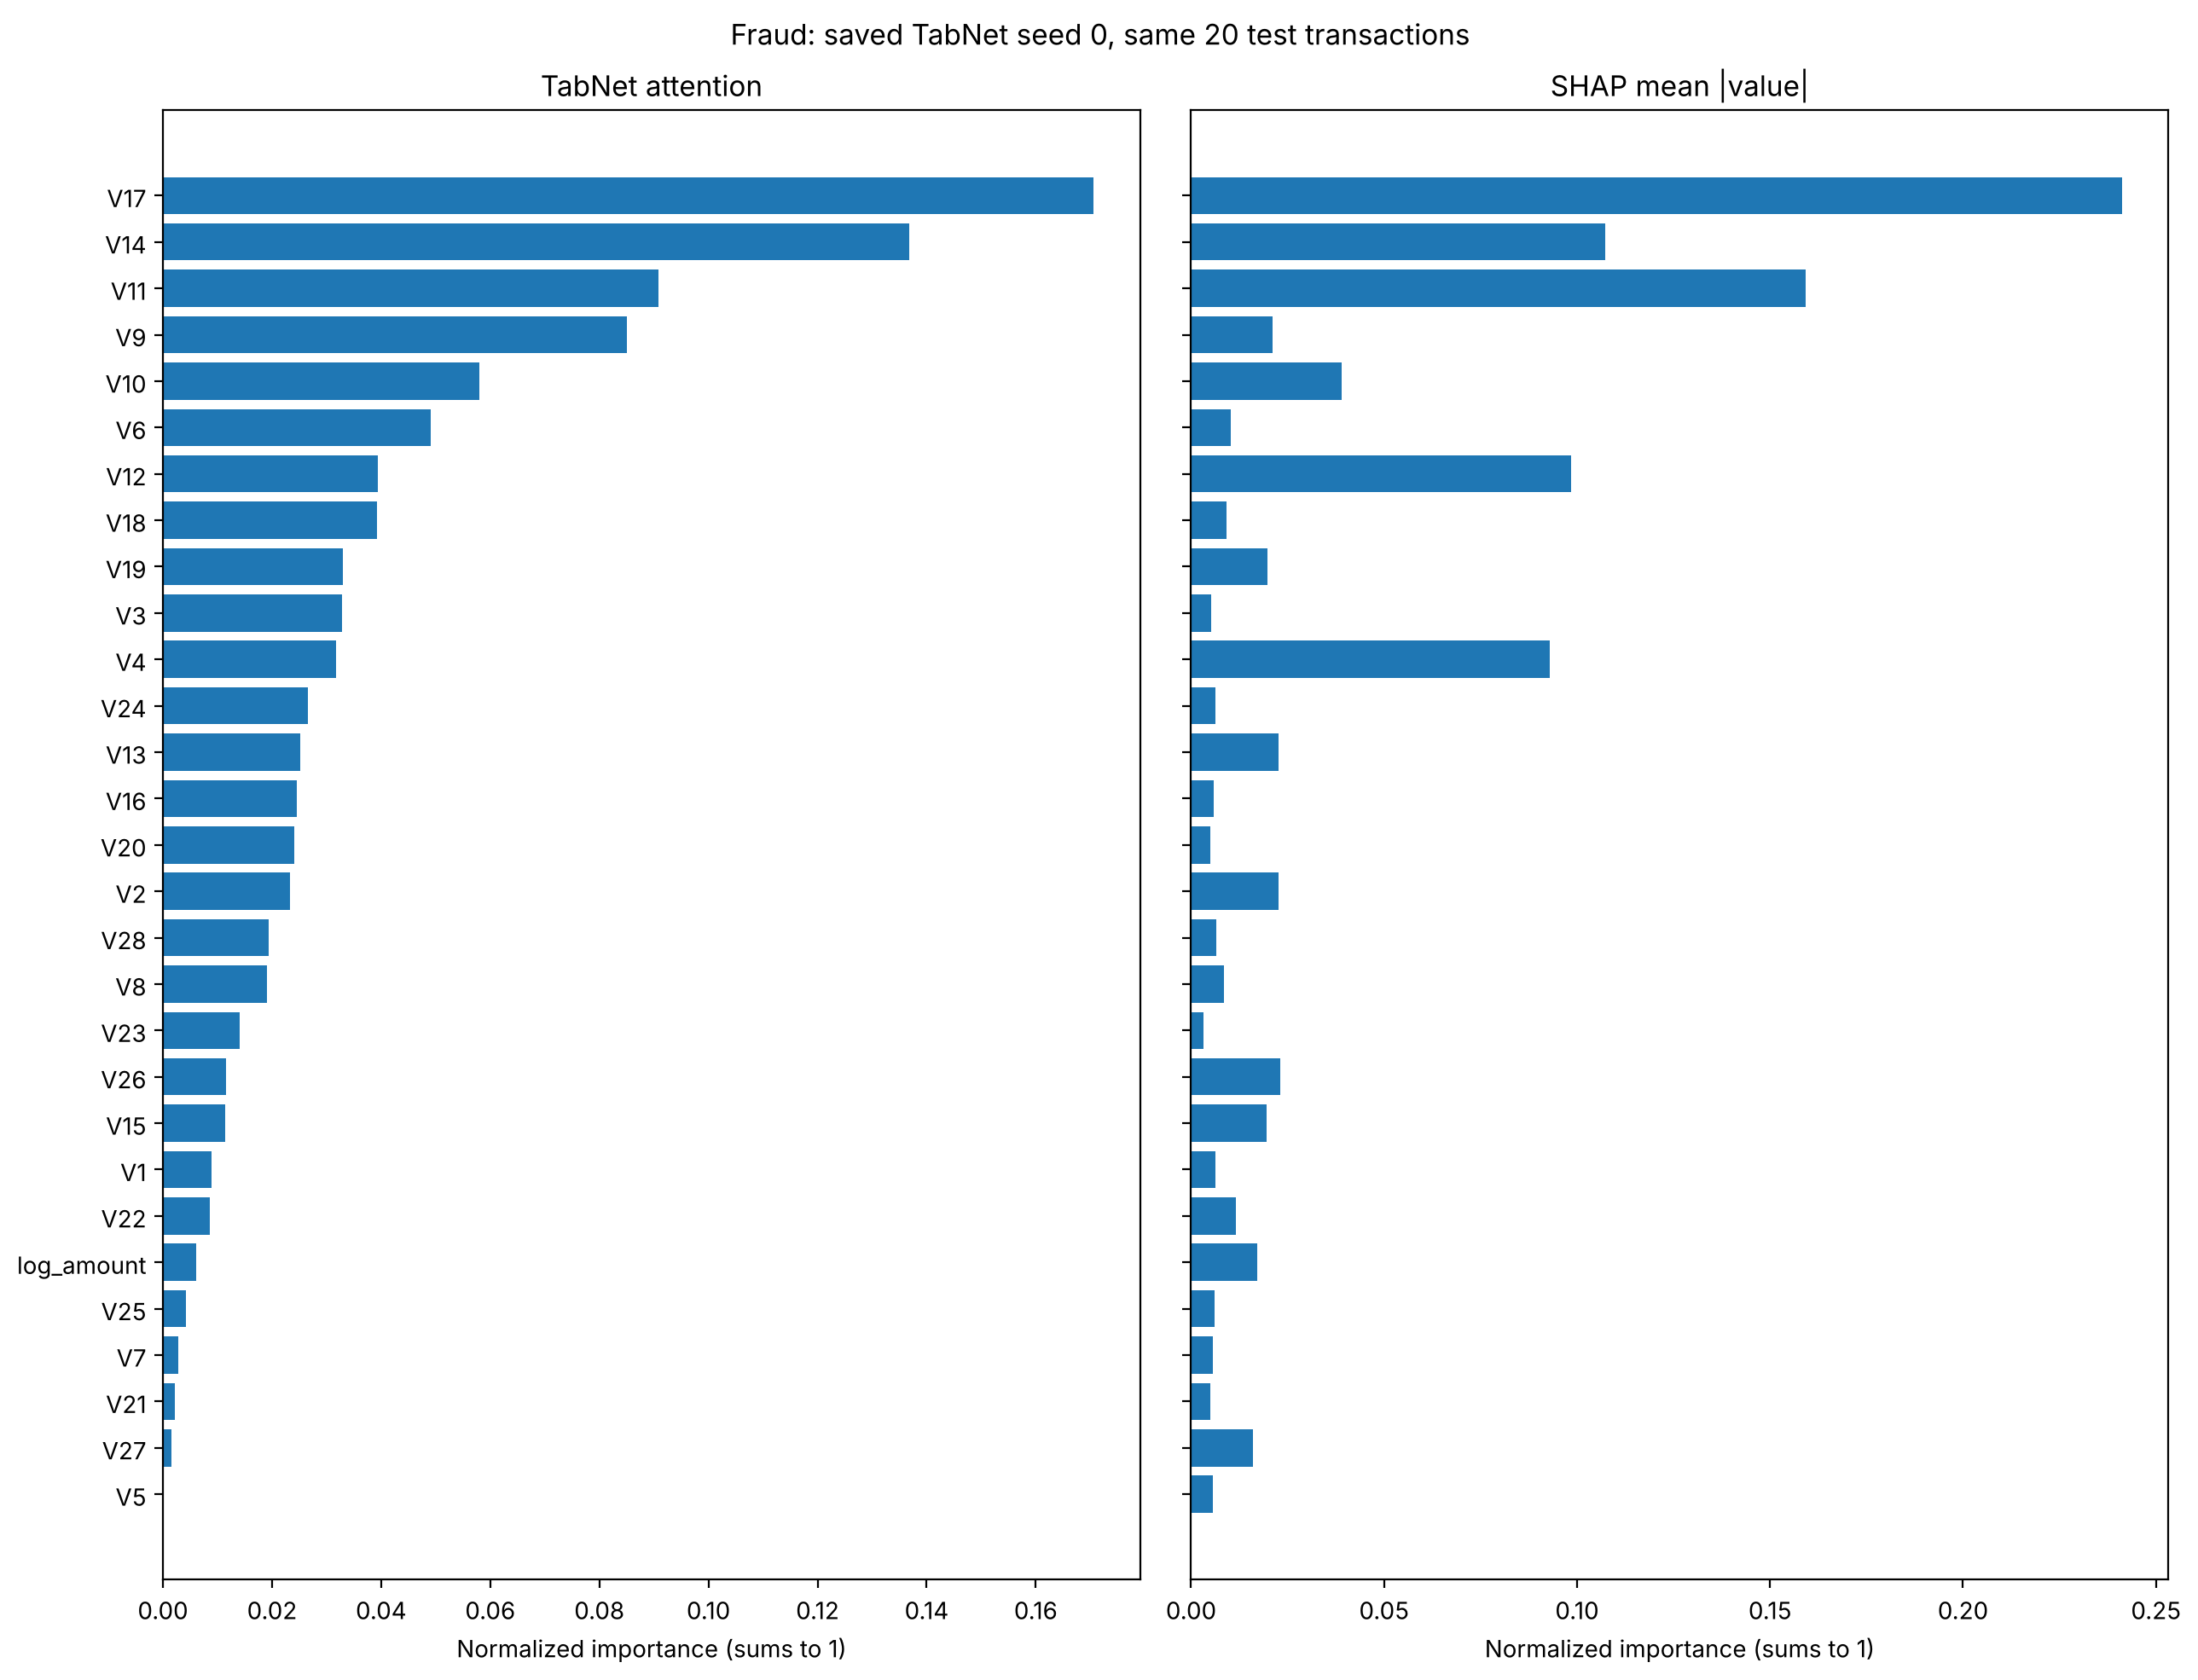

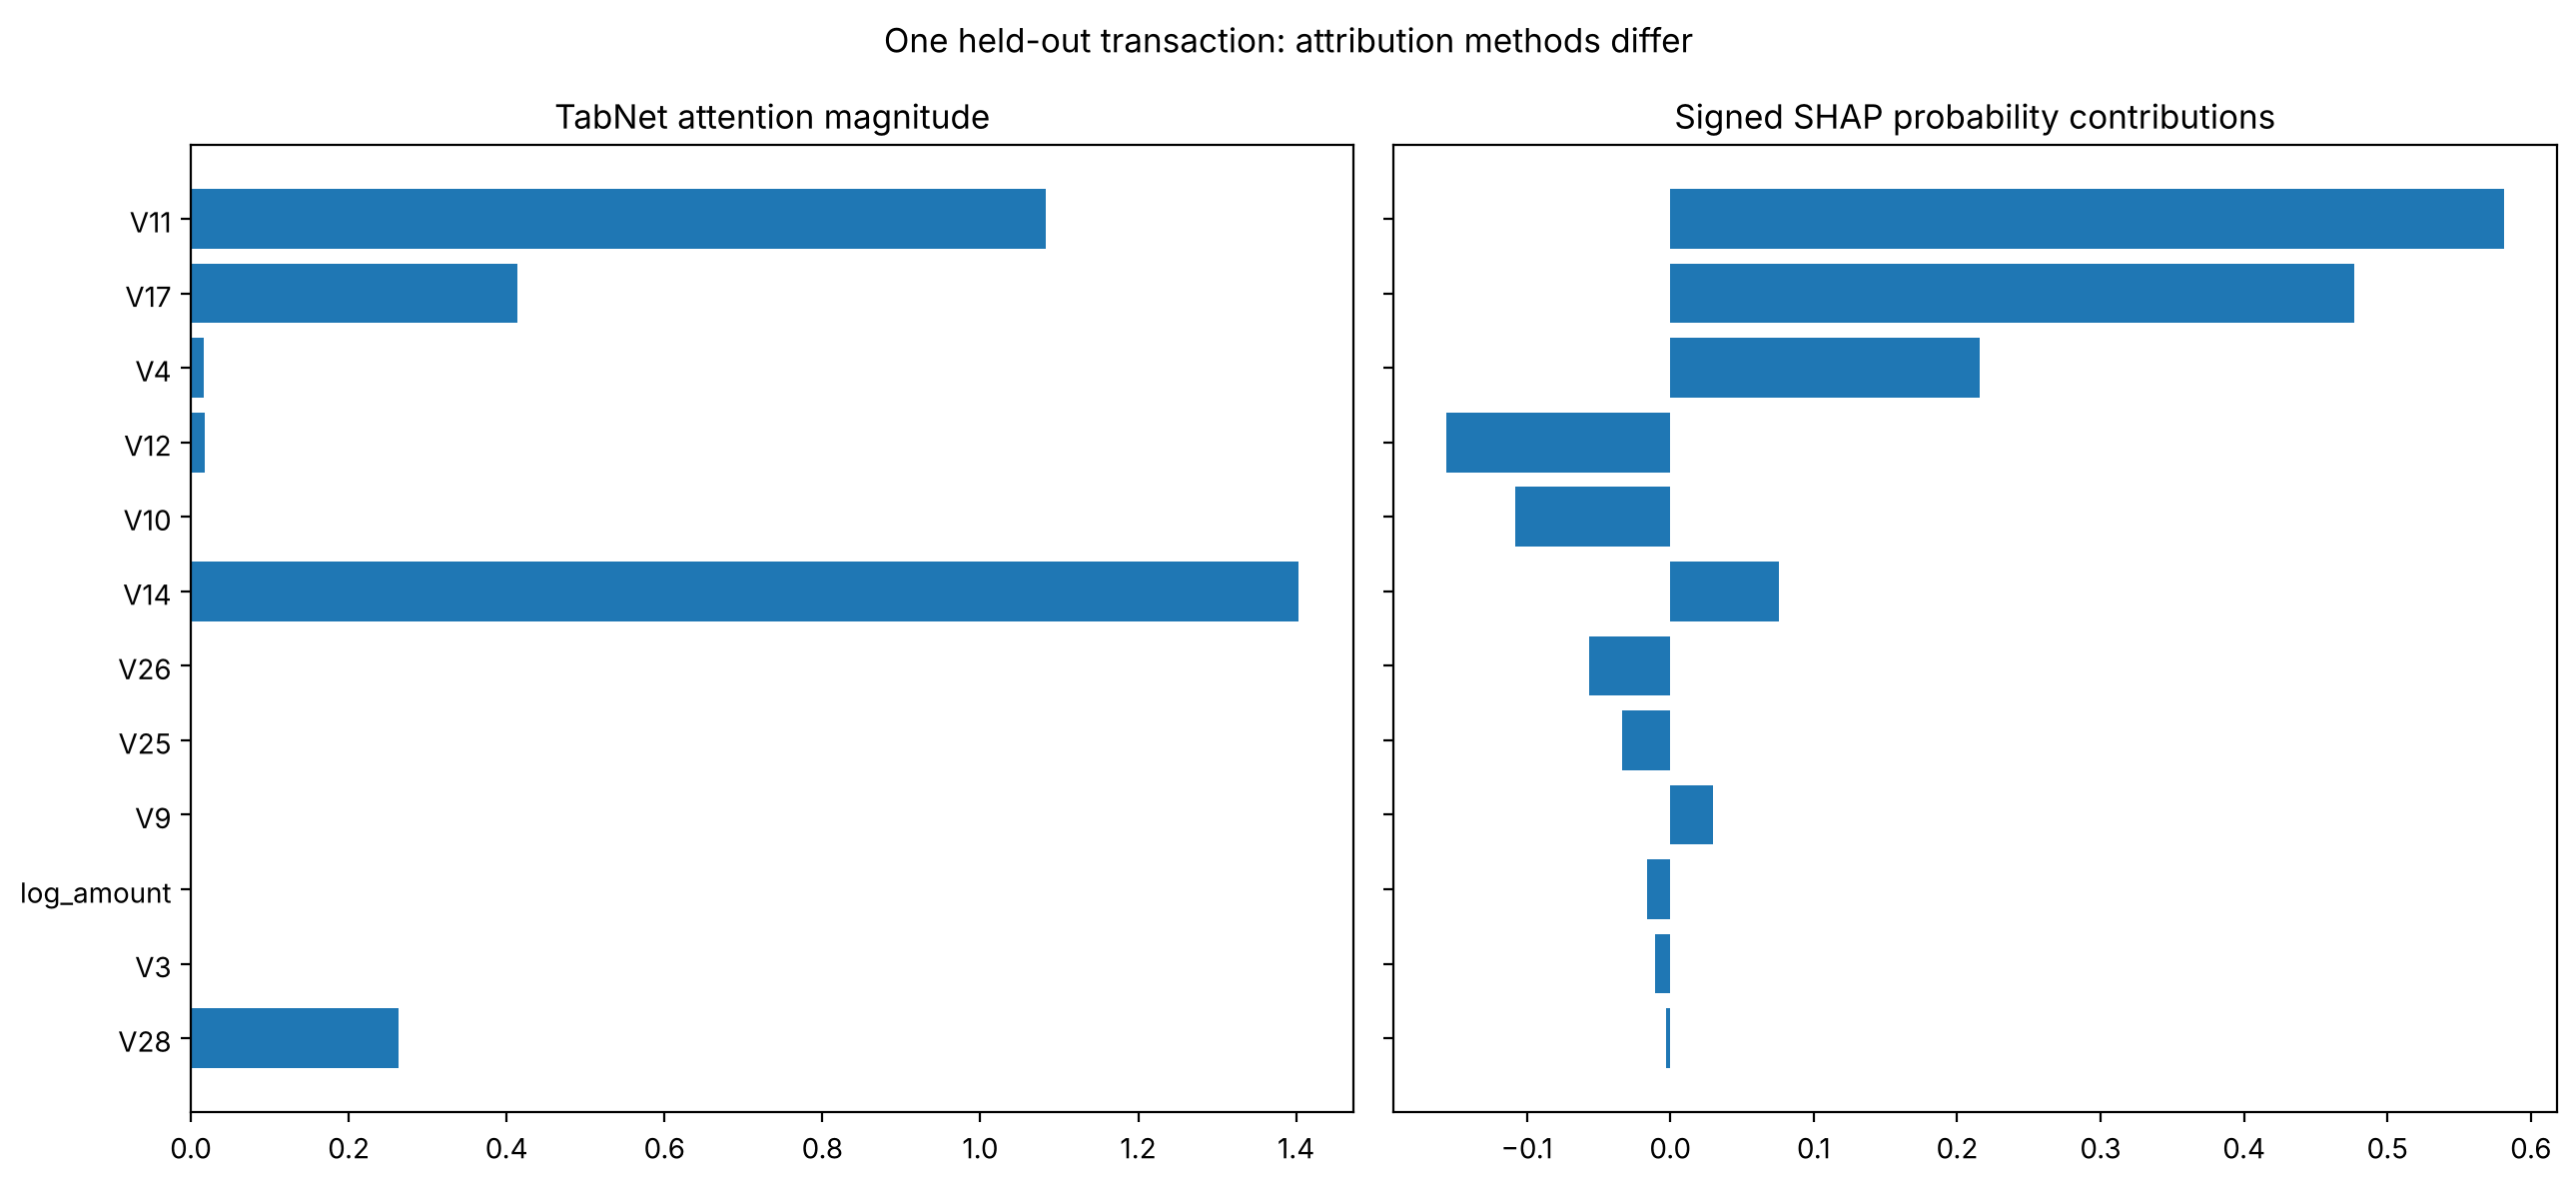

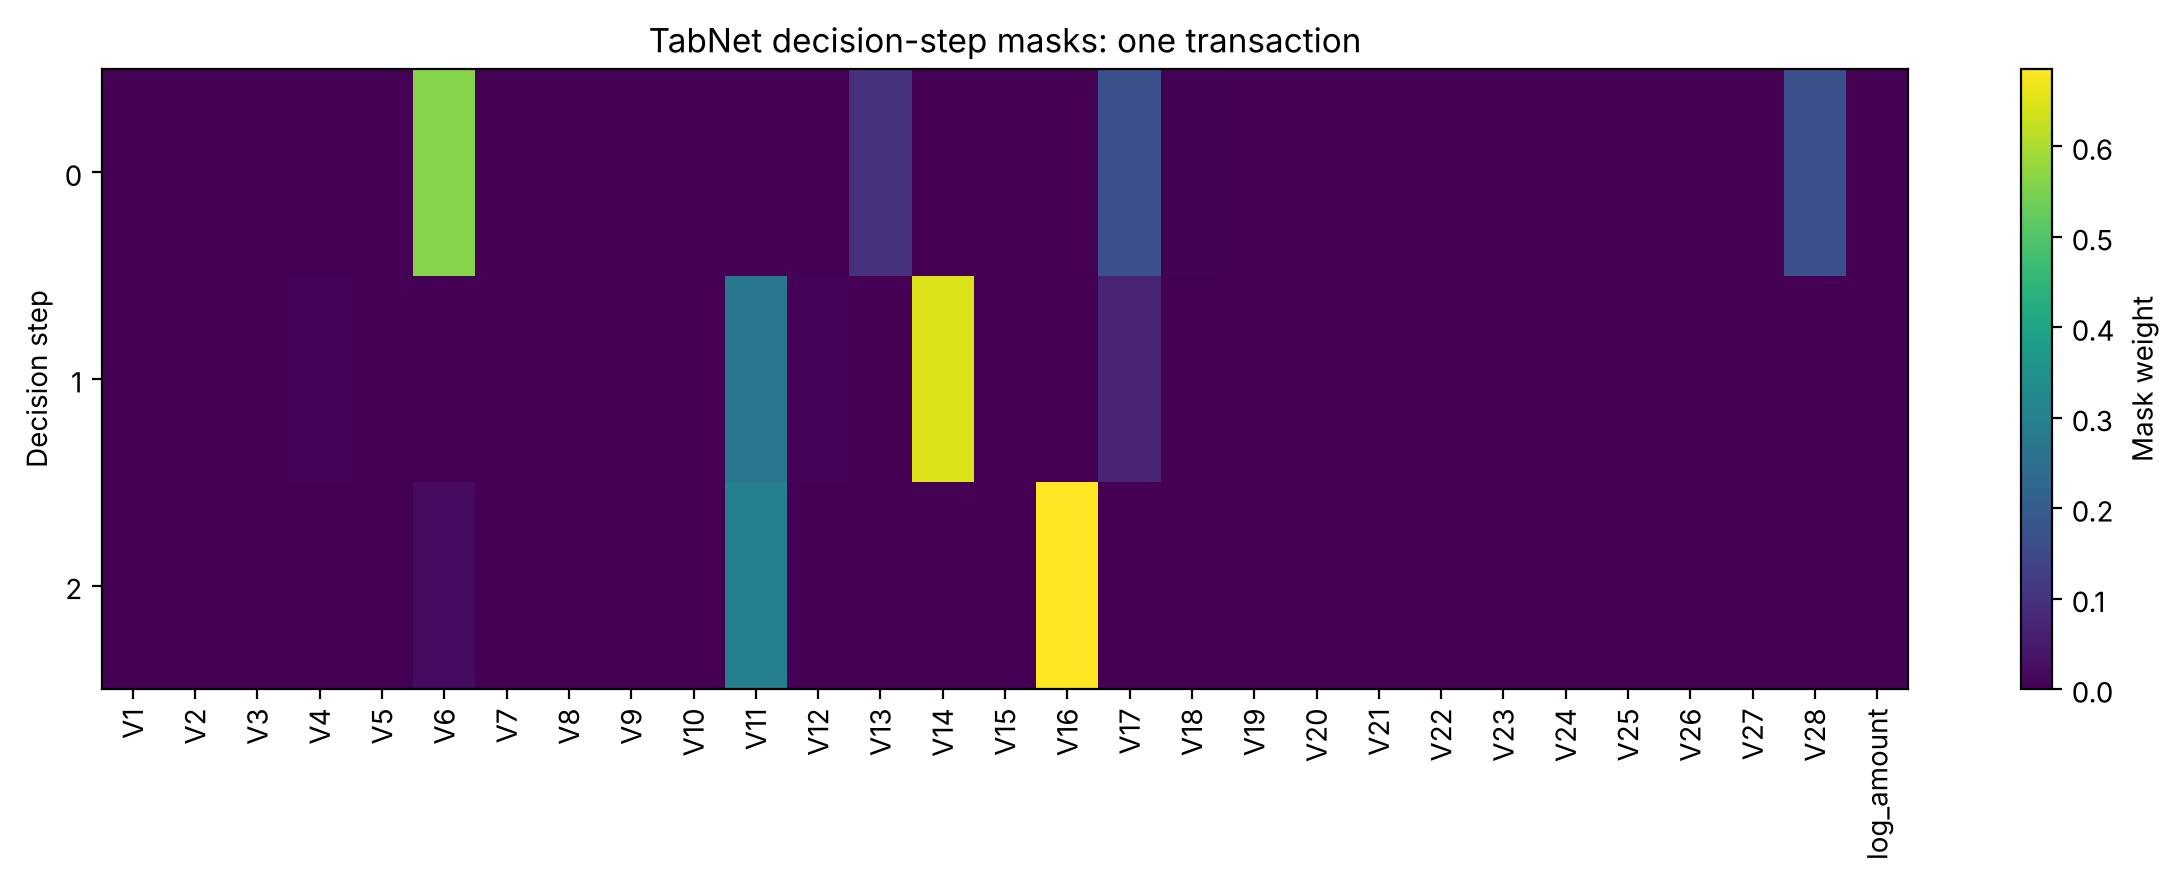

In [6]:
rank_attention=pd.Series(attention_global,index=expected).rank(ascending=False,method='average')
rank_shap=pd.Series(shap_global,index=expected).rank(ascending=False,method='average')
rho,pvalue=spearmanr(rank_attention,rank_shap)

table=pd.DataFrame({'feature':expected,
                    'tabnet_attention':attention_global,
                    'tabnet_attention_normalized':attention_norm,
                    'shap_mean_abs':shap_global,
                    'shap_mean_abs_normalized':shap_norm,
                    'attention_rank':rank_attention.to_numpy(),
                    'shap_rank':rank_shap.to_numpy()})
table=table.sort_values('attention_rank')
table.to_csv(OUT/'tabnet_attention_vs_shap_features.csv',index=False)

print(f'Spearman rank correlation: {rho:.4f} (descriptive; p-value={pvalue:.4g})')
print('Top 10 by attention:')
display(table.head(10))

# Side-by-side normalized global importance for all 29 features
order=np.argsort(-attention_norm)
fig,axes=plt.subplots(1,2,figsize=(13,10),sharey=True)
axes[0].barh(np.arange(len(expected)),attention_norm[order]);axes[0].set_title('TabNet attention')
axes[1].barh(np.arange(len(expected)),shap_norm[order]);axes[1].set_title('SHAP mean |value|')
axes[0].set_yticks(np.arange(len(expected)),[expected[i] for i in order])
axes[0].invert_yaxis()
for ax in axes:ax.set_xlabel('Normalized importance (sums to 1)')
fig.suptitle('Fraud: saved TabNet seed 0, same 20 test transactions')
fig.tight_layout();fig.savefig(FIG/'tabnet_attention_vs_shap_global.png',dpi=180);plt.show()

# Local comparison for first selected fraud transaction
fraud_pos=np.flatnonzero(y_explain==1)
local_i=int(fraud_pos[0]) if len(fraud_pos) else 0
local_att=attention[local_i]
local_shap=shap_matrix[local_i]
local_order=np.argsort(-np.abs(local_shap))[:12]
fig,axes=plt.subplots(1,2,figsize=(13,6),sharey=True)
axes[0].barh(range(len(local_order)),local_att[local_order]);axes[0].set_title('TabNet attention magnitude')
axes[1].barh(range(len(local_order)),local_shap[local_order]);axes[1].set_title('Signed SHAP probability contributions')
axes[0].set_yticks(range(len(local_order)),[expected[i] for i in local_order]);axes[0].invert_yaxis()
fig.suptitle('One held-out transaction: attribution methods differ')
fig.tight_layout();fig.savefig(FIG/'tabnet_attention_vs_shap_local.png',dpi=180);plt.show()

# Per-decision-step masks for same transaction
step_keys=sorted(masks.keys(),key=str)
if step_keys:
    mask_arr=np.vstack([np.asarray(masks[k])[local_i] for k in step_keys])
    fig,ax=plt.subplots(figsize=(12,3+len(step_keys)*0.5))
    im=ax.imshow(mask_arr,aspect='auto',cmap='viridis')
    ax.set_yticks(range(len(step_keys)),[str(k) for k in step_keys]);ax.set_ylabel('Decision step')
    ax.set_xticks(range(len(expected)),expected,rotation=90)
    ax.set_title('TabNet decision-step masks: one transaction')
    fig.colorbar(im,ax=ax,label='Mask weight');fig.tight_layout()
    fig.savefig(FIG/'tabnet_attention_step_masks.png',dpi=180);plt.show()

pd.DataFrame({'test_row_position':chosen,'actual':y_explain,
              'predicted_fraud_probability':predict_fraud_probability(X_explain)}).to_csv(OUT/'tabnet_explained_sample.csv',index=False)
pd.DataFrame([{'spearman_rho':rho,'spearman_pvalue_descriptive':pvalue,
               'n_explained':len(chosen),'n_background':len(X_background),
               'n_features':len(expected),'model_seed':0}]).to_csv(OUT/'tabnet_attention_vs_shap_summary.csv',index=False)


## 7. Save report notes and download ZIP

In [7]:
notes=f"""# TabNet attention vs SHAP: Fraud

- Compared built-in TabNet mask-based attribution and permutation SHAP for the saved **seed-0** TabNet fraud model.
- Used {len(chosen)} held-out transactions (oversampled fraud for interpretation) and {len(X_background)} training-background transactions.
- Spearman correlation between global feature rankings: **{rho:.3f}**.
- Attention scores are nonnegative mask-based importance, while SHAP scores are signed contributions to predicted fraud probability. These are not interchangeable or causal explanations.
- Global importances are normalized independently to sum to one before plotting.
- Because the sample is deliberately class-balanced, global importance is **not representative of the natural fraud distribution**.
- This is an exploratory explanation comparison for one seed, not a cross-seed stability study.
"""
(OUT/'tabnet_attention_vs_shap_interpretation.md').write_text(notes,encoding='utf-8')
print('Saved results to', OUT)

Saved results to /home/claude/work/results/person_b


## GitHub paths

- Notebook: `person_b/04_tabnet_attention_vs_shap.ipynb`
- CSV and Markdown: `results/person_b/`
- PNG images: `results/person_b/figures/`

**Next experiment:** TabNet categorical embeddings vs one-hot on German Credit. This is separate and will require retraining two matched configurations.
